# Musical Trait Drivers of Danceability, Energy, and Popularity

**Author:** Jaash Thakkar · Purdue University

This notebook explores three questions using Spotify audio features for high- and low-popularity tracks:

1. **RQ1:** What drives danceability in low-tempo songs vs. high-tempo songs? (correlation heatmaps)
2. **RQ2:** Do artists with multiple high-popularity tracks show lower variability in their musical traits? (one-sample t-test)
3. **RQ3:** Do different genres achieve energy through the same traits? (global and genre-level Pearson correlations)

**Data:** `high_popularity_spotify_data.csv` and `low_popularity_spotify_data.csv` (see README for the source). Place both files in this folder before running.

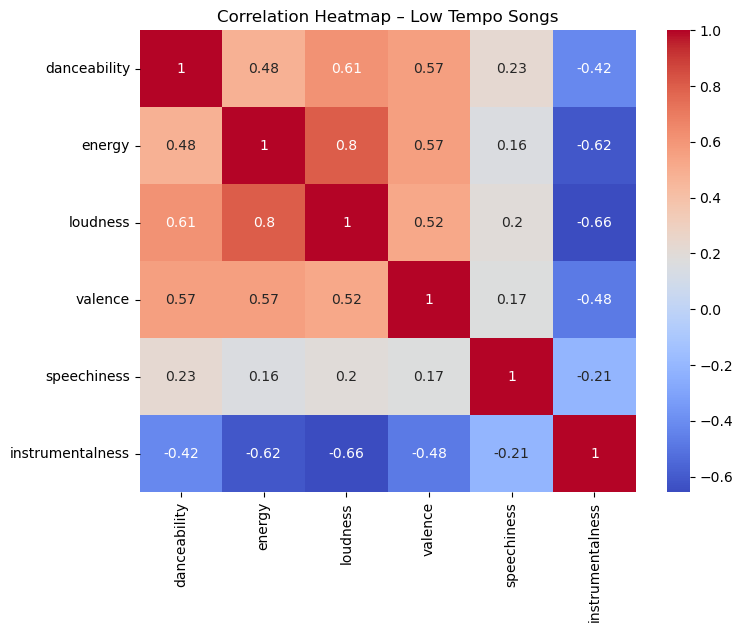

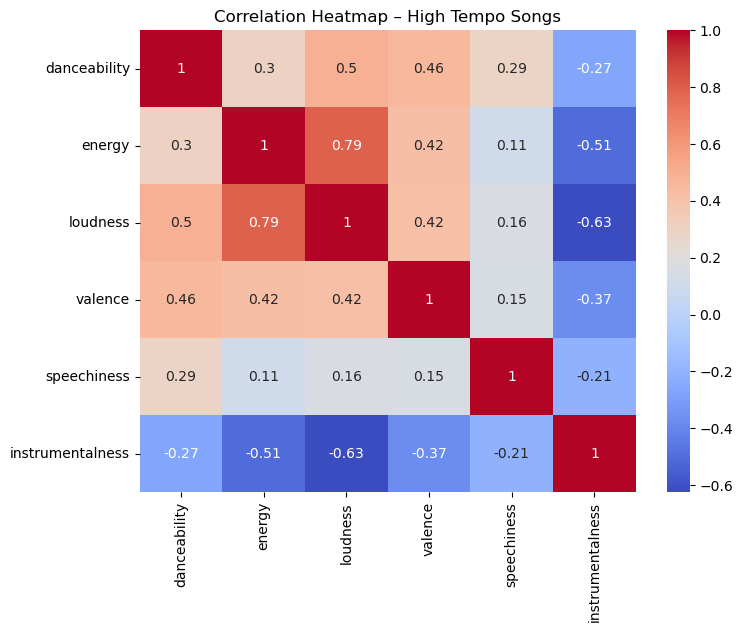


RQ1 Correlations with Danceability (Low Tempo):
danceability        1.000000
loudness            0.614143
valence             0.565530
energy              0.476440
speechiness         0.227895
instrumentalness   -0.422348
Name: danceability, dtype: float64

RQ2 Results:
T-statistic: -26.24
P-value: 4.928213945614208e-81

RQ3 Global Energy Correlations:
energy              1.000000
loudness            0.798847
valence             0.491667
danceability        0.387130
tempo               0.197656
instrumentalness   -0.564715
acousticness       -0.751047
Name: energy, dtype: float64

RQ3 Genre-Specific Primary Energy Drivers:
pop: loudness (r = 0.619)
rock: loudness (r = 0.715)
jazz: loudness (r = 0.65)
classical: loudness (r = 0.848)
hip-hop: loudness (r = 0.607)
afrobeats: loudness (r = 0.528)
latin: loudness (r = 0.763)
indian: loudness (r = 0.715)
country: loudness (r = 0.554)
r&b: loudness (r = 0.711)
electronic: loudness (r = 0.864)
soul: loudness (r = 0.755)
gaming: loudness (r = 

In [1]:
# ==========================================================
# Musical Trait Drivers of Danceability, Energy, and Popularity
# Jaash Thakkar
# GRAD 50500
# ==========================================================

# -----------------------------
# Imports
# -----------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


# ==========================================================
# Load Data
# ==========================================================
high_df = pd.read_csv("high_popularity_spotify_data.csv")
low_df = pd.read_csv("low_popularity_spotify_data.csv")

high_df["popularity_group"] = "high"
low_df["popularity_group"] = "low"

df = pd.concat([high_df, low_df], ignore_index=True)


# ==========================================================
# RQ1 – What Drives Danceability in Low-Tempo Songs?
# ==========================================================

mean_tempo = df["tempo"].mean()
low_tempo_df = df[df["tempo"] < mean_tempo]
high_tempo_df = df[df["tempo"] >= mean_tempo]

features = [
    "danceability","energy","loudness",
    "valence","speechiness","instrumentalness"
]

# Low tempo correlation
corr_low = low_tempo_df[features].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_low, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap – Low Tempo Songs")
plt.show()

# High tempo correlation
corr_high = high_tempo_df[features].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_high, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap – High Tempo Songs")
plt.show()

print("\nRQ1 Correlations with Danceability (Low Tempo):")
print(corr_low["danceability"].sort_values(ascending=False))


# ==========================================================
# RQ2 – Do Repeat High-Popularity Artists Show Lower Variability?
# ==========================================================

artist_std = high_df.groupby("track_artist")[
    ["danceability","energy","loudness",
     "valence","tempo","speechiness","instrumentalness"]
].std()

artist_std["avg_std"] = artist_std.mean(axis=1)
artist_std = artist_std.dropna()

overall_std = df[
    ["danceability","energy","loudness",
     "valence","tempo","speechiness","instrumentalness"]
].std().mean()

repeat_std = artist_std["avg_std"]

t_stat, p_val = stats.ttest_1samp(repeat_std, overall_std)

print("\nRQ2 Results:")
print("T-statistic:", round(t_stat, 2))
print("P-value:", p_val)


# ==========================================================
# RQ3 – Do Genres Achieve Energy Through the Same Traits?
# ==========================================================

energy_features = [
    "energy","loudness","acousticness",
    "instrumentalness","valence",
    "danceability","tempo"
]

# Global correlations
global_corr = df[energy_features].corr()["energy"].sort_values(ascending=False)

print("\nRQ3 Global Energy Correlations:")
print(global_corr)

# Genre-specific correlations
genre_results = {}

for genre in df["playlist_genre"].unique():
    genre_df = df[df["playlist_genre"] == genre]
    corr = genre_df[energy_features].corr()["energy"].sort_values(ascending=False)
    genre_results[genre] = corr

print("\nRQ3 Genre-Specific Primary Energy Drivers:")
for genre, corr in genre_results.items():
    print(f"{genre}: {corr.index[1]} (r = {round(corr.iloc[1],3)})")

## Key results

- **RQ1:** In low-tempo songs, danceability is most strongly associated with loudness (r = 0.61) and valence (r = 0.57), and negatively with instrumentalness (r = −0.42).
- **RQ2:** Artists with repeat high-popularity tracks are significantly more consistent than the dataset overall (t = −26.24, p < 0.001).
- **RQ3:** Loudness is the strongest driver of energy overall (r = 0.80) and in every genre analyzed; acousticness is the strongest negative driver (r = −0.75).